# Proyecto integrador — Módulo I
## Precios, géneros y participación en videojuegos de Steam

**Preguntas de investigación**

1. ¿Cómo se distribuyen los precios y qué diferencias existen entre géneros?
2. ¿Qué géneros concentran más videojuegos y cuáles presentan mayores niveles de participación?

**Procedencia:** *SteamGames (71k games)*, publicado por **mexwell** en Kaggle: https://www.kaggle.com/datasets/mexwell/steamgames

**Alcance del archivo analizado:** `games.csv` suministrado para el proyecto, con **71,716 registros y 39 columnas originales**. 
**Unidad de observación:** videojuego / aplicación en Steam, identificada por `AppID`.

**Justificación de la base:** contiene precios, géneros, reseñas y medidas de concurrencia, por lo que es adecuada para describir distribuciones de precios, tamaños por género y diferencias en participación.

**Definiciones metodológicas importantes:**

- Los precios se interpretan en **USD**, conforme a la descripción de variables de esta colección; son precios registrados en el conjunto, no necesariamente actuales.
- Se entiende *participación* como concurrencia de jugadores mediante `Peak CCU` (pico de jugadores simultáneos registrado), **no ventas, propietarios únicos ni jugadores acumulados**. 
- Para comparar grupos utilizaremos **porcentaje de juegos con `Peak CCU > 0`** y **mediana de `Peak CCU` entre los que tienen valores positivos**. Los ceros se conservarán y reportarán por separado; no sabemos si representan inactividad o limitaciones de medición.
- Un juego puede tener **varios géneros**. Por ello, al contabilizar los géneros un mismo `AppID` puede aparecer en varios grupos; la suma de cantidades de géneros **no debe interpretarse como cantidad de juegos distintos**.



## Comprensión de los datos

La fuente se encuentra en la página de Kaggle indicada al inicio. La base original incluye 39 columnas; trabajamos con un subconjunto de 7 columnas porque las preguntas requieren identificar videojuegos, precios, géneros, reseñas y participación. La reducción de columnas **no implica eliminar observaciones**.

### Importar bibliotecas
Debemos disponer de herramientas para archivos, datos numéricos, tablas y visualizaciones.

### Definir carpetas de entrada y salida

Usaremos rutas relativas para que cualquier integrante pueda ejecutar el repositorio. 
Documentos necesarios:
- games.csv
- games_tools.py

Creamos el directorio en donde se guardaran los resultados.

In [30]:

# Importa pandas para trabajar con tablas y archivos CSV (se conserva esta importación original).
import pandas as pd
#maneja rutas de archivos
from pathlib import Path
#Nos servirá para el manejo de datos numéricos
import numpy as np
#o utilizaremos para cargar, explorar, limpiar, agrupar y exportar las tablas:
import pandas as pd
#servirá para elaborar y guardar los gráficos:
import matplotlib.pyplot as plt
#manejo de rutas de archivos
import sys

# Busca la carpeta raíz: comienza en el directorio actual y también revisa sus carpetas superiores.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             # Exige que exista el archivo auxiliar games_tools.py dentro de la carpeta Proyecto.
             if (p / "Proyecto" / "games_tools.py").is_file()
             # También exige que la misma raíz contenga el archivo de datos games.csv.
             and (p / "Proyecto" / "games.csv").is_file()), None)
# Si no se cumplen ambas condiciones, no es posible determinar la ubicación del proyecto.
if ROOT is None:
    # Detiene la ejecución con un mensaje que ayuda a revisar la organización de archivos.
    raise FileNotFoundError(
        "No encuentro Python/games_tools.py y Proyecto/games.csv "
        "Abre en VS Code la carpeta 'Proyecto' y selecciona su kernel."
    )
# Construye la ruta hacia la carpeta Python, donde el script espera localizar los módulos auxiliares.
PYTHON_DIR = ROOT / "Python"
# Comprueba si Python ya tiene incluida esa carpeta en su lista de rutas de importación.
if str(PYTHON_DIR) not in sys.path:
    # Agrega la ruta al inicio para poder importar módulos desde esa carpeta.
    sys.path.insert(0, str(PYTHON_DIR))
# Importa las funciones auxiliares del equipo sin sustituir la dependencia games_tools.
from games_tools import (read_tables, build_order_level, build_item_level,
                        table_inventory, missing_profile, safe_minmax, safe_zscore)
# Ejecuta la función auxiliar que devuelve las tablas y la descripción de su origen.
TABLAS, ORIGEN = read_tables(ROOT)
# Muestra de dónde proceden los datos según la función auxiliar.
print("ORIGEN:", ORIGEN)
# Muestra la ruta raíz encontrada por el código.
print("Directorio raíz:", ROOT)

# Crea la carpeta de resultados dentro de Proyecto.
SALIDA = ROOT / "Proyecto" / "Resultados"
# Crea esa carpeta y sus superiores cuando hagan falta; no falla si ya existe.
SALIDA.mkdir(parents=True, exist_ok=True)

# Muestra la ubicación del CSV que se utilizará en las siguientes celdas.
print("Archivo utilizado:", ROOT / "Proyecto" / "games.csv")
# Muestra la carpeta donde se guardarán las tablas y visualizaciones.
print("Carpeta de resultados:", SALIDA)


ORIGEN: CSV reales suministrados: Proyecto/games.csv
Directorio raíz: /Users/josue_castellanos
Archivo utilizado: /Users/josue_castellanos/Proyecto/games.csv
Carpeta de resultados: /Users/josue_castellanos/Proyecto/Resultados


**Interpretación breve:** Se identificó la carpeta raíz del proyecto, se mantuvo el uso de `games_tools` y se preparó la carpeta donde se guardarán los resultados. Este bloque configura la lectura y las salidas


# Preprocesamiento de los datos
(Josué Alfredo Castellanos Cruz)


## Diagnóstico inicial de los datos
En este apartado revisamos la estructura de la base de datos games.csv y evaluamos la calidad de las variables relevantes para nuestras preguntas de negocio. Para ello, verificamos que AppID identifique cada registro de forma única y revisamos los tipos de datos, los valores faltantes, los formatos de fecha, los intervalos de propietarios estimados y la presencia de ceros y valores extremos.

Este diagnóstico nos permite identificar qué características podrían afectar los resultados. Por ejemplo, algunas fechas solo indican el mes y el año, por lo que sirven para un análisis mensual, pero carecen de la precisión necesaria para uno diario. Con estos hallazgos definimos qué transformaciones aplicar, qué valores requieren validación y qué limitaciones debemos considerar al interpretar los resultados.

In [31]:
# Lee las 39 columnas originales desde la carpeta ya definida en Proyecto_games.
# Se cambia únicamente la ruta original 'games.csv' por la ubicación ROOT/Proyecto/games.csv.
games = pd.read_csv(ROOT / "Proyecto" / "games.csv", low_memory=False)

# Muestra las cinco primeras filas para verificar que el archivo se leyó correctamente.
display(games.head(5))


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,DLC count,About the game,Supported languages,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,20200,Galactic Bowling,"Oct 21, 2008",0 - 20000,0,0,19.99,0,Galactic Bowling is an exaggerated and stylize...,['English'],...,0,0,0,Perpetual FX Creative,Perpetual FX Creative,"Single-player,Multi-player,Steam Achievements,...","Casual,Indie,Sports","Indie,Casual,Sports,Bowling",https://cdn.akamai.steamstatic.com/steam/apps/...,http://cdn.akamai.steamstatic.com/steam/apps/2...
1,655370,Train Bandit,"Oct 12, 2017",0 - 20000,0,0,0.99,0,THE LAW!! Looks to be a showdown atop a train....,"['English', 'French', 'Italian', 'German', 'Sp...",...,0,0,0,Rusty Moyher,Wild Rooster,"Single-player,Steam Achievements,Full controll...","Action,Indie","Indie,Action,Pixel Graphics,2D,Retro,Arcade,Sc...",https://cdn.akamai.steamstatic.com/steam/apps/...,http://cdn.akamai.steamstatic.com/steam/apps/2...
2,1732930,Jolt Project,"Nov 17, 2021",0 - 20000,0,0,4.99,0,Jolt Project: The army now has a new robotics ...,"['English', 'Portuguese - Brazil']",...,0,0,0,Campião Games,Campião Games,Single-player,"Action,Adventure,Indie,Strategy",NaN,https://cdn.akamai.steamstatic.com/steam/apps/...,http://cdn.akamai.steamstatic.com/steam/apps/2...
3,1355720,Henosis™,"Jul 23, 2020",0 - 20000,0,0,5.99,0,HENOSIS™ is a mysterious 2D Platform Puzzler w...,"['English', 'French', 'Italian', 'German', 'Sp...",...,0,0,0,Odd Critter Games,Odd Critter Games,"Single-player,Full controller support","Adventure,Casual,Indie","2D Platformer,Atmospheric,Surreal,Mystery,Puzz...",https://cdn.akamai.steamstatic.com/steam/apps/...,http://cdn.akamai.steamstatic.com/steam/apps/2...
4,1139950,Two Weeks in Painland,"Feb 3, 2020",0 - 20000,0,0,0.00,0,ABOUT THE GAME Play as a hacker who has arrang...,"['English', 'Spanish - Spain']",...,0,0,0,Unusual Games,Unusual Games,"Single-player,Steam Achievements","Adventure,Indie","Indie,Adventure,Nudity,Violent,Sexual Content,...",https://cdn.akamai.steamstatic.com/steam/apps/...,http://cdn.akamai.steamstatic.com/steam/apps/2...


**Interpretación breve:** Se revisa el archivo completo (`games.csv`) con sus **71,716 registros y 39 columnas**. Esta revisión amplia sirve para diagnosticar la calidad de los datos; **no reemplaza** al `df` de siete variables que cargará enseguida el notebook principal.

In [32]:
# Muestra cuántos registros y columnas tiene el CSV completo.
print(f'La base de datos games tiene {games.shape[0]} filas y {games.shape[1]} columnas')

# Presenta un encabezado que identifica el diagnóstico de variables.
print('Nombres de las variables y sus tipos de datos:')
# Crea una tabla de diagnóstico para cada una de las 39 columnas originales.
perfil = pd.DataFrame({
    # Convierte el tipo de cada columna en texto legible.
    "tipo_de_dato": games.dtypes.astype(str),
    # Cuenta las celdas sin información por columna.
    "faltantes": games.isna().sum(),
    # Cuenta los valores diferentes de cada columna, excluyendo los faltantes.
    "valores_distintos": games.nunique()
})
# Muestra el perfil completo de los datos.
display(perfil)

# Agrupa por nombre de la aplicación y cuenta los identificadores AppID diferentes.
appids_por_nombre = games.groupby("Name")["AppID"].nunique()
# Selecciona solo nombres que están asociados a más de un identificador.
nombres_repetidos = (
    # Conserva nombres con dos o más AppID distintos.
    appids_por_nombre[appids_por_nombre.gt(1)]
    # Ordena los nombres desde el que tiene más AppID distintos.
    .sort_values(ascending=False)
    # Asigna un nombre claro a la columna/serie resultante.
    .rename("AppID_distintos")
)

# Presenta el resumen de nombres que corresponden a varios identificadores.
print("\nNombres asociados con más de un AppID:")
# Muestra únicamente los quince casos con mayor número de identificadores.
display(nombres_repetidos.head(15))


La base de datos games tiene 71716 filas y 39 columnas
Nombres de las variables y sus tipos de datos:


,tipo_de_dato,faltantes,valores_distintos
AppID,int64,0,71716
Name,object,1,71170
Release date,object,0,4170
Estimated owners,object,0,14
Peak CCU,int64,0,1298
Required age,int64,0,17
Price,float64,0,515
DLC count,int64,0,94
About the game,object,2436,68942
Supported languages,object,0,9663



Nombres asociados con más de un AppID:


Name
Shadow of the Tomb Raider: Definitive Edition    20
Train Simulator Classic                           5
Alone                                             5
Escape                                            5
Tom Clancy's Rainbow Six® Siege                   5
Aurora                                            4
Space Survival                                    4
Lost                                              4
Bounce                                            4
Jewel Quest Pack                                  4
Nightmare                                         4
Hide and Seek                                     4
Celestial                                         3
Dodge                                             3
Spectrum                                          3
Name: AppID_distintos, dtype: int64

**Interpretación breve:** El archivo contiene **71,716 registros y 39 columnas**. Hay **un nombre faltante** y algunos nombres se asocian con varios `AppID` diferentes; por ello, la identificación de juegos debe basarse en `AppID` y no únicamente en `Name`. La tabla también ayuda a detectar faltantes en variables complementarias.

In [33]:
# Toma la columna de fecha, la convierte a texto y elimina espacios externos.
fecha = games["Release date"].astype("string").str.strip()

# Identifica fechas que incluyen mes abreviado, día y año; por ejemplo, Oct 21, 2008.
con_dia = fecha.str.fullmatch(r"[A-Za-z]{3} \d{1,2}, \d{4}", na=False)
# Muestra la cantidad de fechas que cumplen el formato completo.
print(f"Cantidad de fechas con día, mes y año: {con_dia.sum()}")

# Detecta fechas que no cumplen el formato de día, mes y año.
que_otro_formato = ~con_dia
# Cuenta las fechas restantes, independientemente de cuál sea su formato.
print(f"Cantidad de fechas con otro formato: {que_otro_formato.sum()}")
# Muestra hasta diez ejemplos distintos de formatos diferentes al completo.
display(fecha[que_otro_formato].drop_duplicates().head(10))

# Detecta fechas que contienen solo mes abreviado y año; por ejemplo, Nov 2021.
solo_mes = fecha.str.fullmatch(r"[A-Za-z]{3} \d{4}", na=False)
# Marca formatos que no pertenecen a ninguno de los dos patrones anteriores.
otro_formato = ~(con_dia | solo_mes)

# Construye una serie con los conteos de cada formato y el total de fechas presentes.
resumen_fechas = pd.Series({
    "Día, mes y año": con_dia.sum(),  # Registros con fecha diaria.
    "Mes y año": solo_mes.sum(),      # Registros que carecen de día específico.
    "Otro formato": otro_formato.sum(),  # Registros que necesitan revisión adicional.
    "Total": fecha.notna().sum()     # Total de fechas no faltantes.
})

# Muestra el resumen final de formatos en texto.
print(resumen_fechas.to_string())


Cantidad de fechas con día, mes y año: 71592
Cantidad de fechas con otro formato: 124


92      May 2020
145     Aug 2020
536     Mar 2017
1245    Dec 2012
1464    Jun 2021
1928    May 2021
1990    Jan 2019
2072    Aug 2014
2464    Nov 2014
2687    Jul 2018
Name: Release date, dtype: string

Día, mes y año    71592
Mes y año           124
Otro formato          0
Total             71716


**Interpretación breve:** Se encontraron **71,592** fechas con día, mes y año, y **124** con solo mes y año; no se detectaron otros formatos. Conviene evitar asignar un día ficticio a las 124 fechas incompletas. Esta limitación importa para análisis por fecha exacta.

In [34]:
# Convierte los rangos de propietarios estimados en texto y elimina espacios externos.
propietarios = games["Estimated owners"].astype("string").str.strip()

# Extrae los límites inferior y superior de cadenas con formato 'número - número'.
# Los grupos con nombre capturan cada extremo y .astype('Int64') admite faltantes.
limites = propietarios.str.extract(
    r"^(?P<limite_inferior>\d+)\s*-\s*(?P<limite_superior>\d+)$"
).astype("Int64")

# Detecta intervalos con ambos límites presentes y límite inferior no superior al mayor.
intervalos_validos = (
    # Ambas columnas de límites deben estar presentes.
    limites.notna().all(axis=1)
    # El límite inferior debe ser menor o igual al superior.
    & limites["limite_inferior"].le(limites["limite_superior"]).fillna(False)
)

# Resume cuántas aplicaciones corresponden a cada intervalo válido.
resumen_intervalos = (
    # Excluye los registros que no cumplen el formato de intervalo.
    limites.loc[intervalos_validos]
    # Cuenta las combinaciones de límites inferior y superior.
    .value_counts()
    # Identifica la columna de conteos como 'registros'.
    .rename("registros")
    # Convierte el resultado en tabla para poder agregar otras columnas.
    .reset_index()
)

# Agrega el punto medio como aproximación descriptiva del intervalo, no como dato exacto.
resumen_intervalos["punto_medio"] = (
    resumen_intervalos["limite_inferior"]  # Extremo inferior.
    + resumen_intervalos["limite_superior"] # Se suma el extremo superior.
) / 2  # Divide entre dos para obtener el punto medio.

# Informa cuántos intervalos diferentes se encontraron.
print("Intervalos distintos:", len(resumen_intervalos))
# Cuenta los valores originales presentes que no pudieron convertirse en intervalos válidos.
print("Valores presentes con intervalo inválido:",
      (propietarios.notna() & ~intervalos_validos).sum())
# Muestra los intervalos, su frecuencia y su punto medio.
display(resumen_intervalos)


Intervalos distintos: 14
Valores presentes con intervalo inválido: 0


,limite_inferior,limite_superior,registros,punto_medio
0,0,20000,47372,10000.0
1,20000,50000,7286,35000.0
2,0,0,7113,0.0
3,50000,100000,3632,75000.0
4,100000,200000,2426,150000.0
5,200000,500000,2041,350000.0
6,500000,1000000,876,750000.0
7,1000000,2000000,501,1500000.0
8,2000000,5000000,319,3500000.0
9,5000000,10000000,86,7500000.0


**Interpretación breve:** Aparecen **14 intervalos válidos** de propietarios estimados y **ningún intervalo con formato inválido**. Destacan `0 - 20000` (47,372 registros) y `0 - 0` (7,113). El punto medio es una aproximación, no el número real de propietarios. La decisión de interpretar `0 - 0` como ausencia de propietarios debe documentarse como supuesto y no confundirse con una medición comprobada.

Observe que hay 14 intervalos, incluyendo 0 - 20000 con 47,372 registros y 0 - 0 con 7,113. El punto medio de 0 - 20000 es 10,000, una aproximación común a todos los registros de ese intervalo. observe que los registros con 0 - 0  es necesario tomar una decision para identificar cómo tratar estos datos. Nuestra decision sera considerar que no tiene owners

In [35]:
# Selecciona cuatro variables numéricas para revisar faltantes, ceros y extremos.
metricas = games[["Peak CCU", "Required age", "Price", "DLC count"]]

# Construye una tabla de medidas descriptivas para cada una de las variables.
resumen_numerico = pd.DataFrame({
    "faltantes": metricas.isna().sum(),  # Cuenta las observaciones sin dato.
    "ceros": metricas.eq(0).sum(),  # Cuenta cuántos valores son exactamente cero.
    "porcentaje_ceros": (
        # Divide los ceros entre los registros no faltantes y expresa el resultado en porcentaje.
        100 * metricas.eq(0).sum() / metricas.count()
    ).round(2),  # Redondea el porcentaje a dos decimales.
    "negativos": metricas.lt(0).sum(),  # Cuenta valores menores que cero.
    "mínimo": metricas.min(),  # Muestra el menor valor registrado.
    "mediana": metricas.median(),  # Muestra el valor central de la distribución.
    "media": metricas.mean().round(2),  # Calcula el promedio y lo redondea.
    "percentil_99": metricas.quantile(0.99).round(2),  # Ubica el percentil 99.
    "máximo": metricas.max()  # Muestra el valor máximo registrado.
})

# Muestra la tabla de medidas numéricas.
display(resumen_numerico)

# Identifica la distribución de las edades requeridas, incluyendo valores cero.
print("\nEdades mínimas registradas:")
# Cuenta cada edad y presenta los valores de menor a mayor.
display(games["Required age"].value_counts(dropna=False).sort_index())

# Identifica las cinco aplicaciones que tienen el mayor número de contenidos descargables.
print("\nCinco aplicaciones con más DLC:")
# Muestra el identificador, el nombre y el número de DLC de las cinco primeras.
display(games.nlargest(5, "DLC count")[["AppID", "Name", "DLC count"]])


,faltantes,ceros,porcentaje_ceros,negativos,mínimo,mediana,media,percentil_99,máximo
Peak CCU,0,52032,72.55,0,0.0,0.00,140.76,848.55,872138.0
Required age,0,70200,97.89,0,0.0,0.00,0.34,17.00,21.0
Price,0,12410,17.30,0,0.0,4.99,7.22,39.99,999.0
DLC count,0,60866,84.87,0,0.0,0.00,0.62,7.00,2366.0



Edades mínimas registradas:


Required age
0     70200
1         1
3         8
5         1
6         6
7         7
10       32
12       30
13      183
14        4
15        8
16       63
17      856
18      310
19        1
20        1
21        5
Name: count, dtype: int64


Cinco aplicaciones con más DLC:


,AppID,Name,DLC count
32933,1196310,Fantasy Grounds Unity,2366
23291,252690,Fantasy Grounds Classic,1968
7575,221680,Rocksmith® 2014 Edition - Remastered,1555
3492,24010,Train Simulator Classic,678
6690,24049,Train Simulator Classic,678


**Interpretación breve:** Se observan muchos ceros en `Peak CCU` (**52,032**), `Required age` (**70,200**), `Price` (**12,410**) y `DLC count` (**60,866**). No hay valores negativos en estas cuatro variables. Sus máximos son elevados respecto a sus medianas, por lo que un valor extremo no debe eliminarse sin revisar su significado; especialmente, cero en `Peak CCU` no demuestra que un juego nunca haya tenido jugadores.

# Valores que debemos validar

| Columna | Ceros | observaciones |
|---|---:|---|
| `Peak CCU` | 52,032 | Si los ceros representan ausencia de jugadores o ausencia de medición, y cuál fue el periodo de observación. |
| `Required age` | 70,200 | Si `0` significa que no se indicó restricción o que el dato quedó sin informar. |
| `Price` | 12,410 | Si todos los ceros representan aplicaciones gratuitas y cuál es la moneda y fecha del precio. |
| `DLC count` | 60,866 | Compara mediana, percentil 99 y máximo. El máximo observado es **2,366**, y la tabla de los cinco mayores permite ver qué aplicaciones concentran esos extremos. |

# Decisiones

## Identificación y características comerciales
| Columna | Tipo | Qué contiene | Qué puede dificultar el análisis |
|---|---|---|---|
| `AppID` | Entero, identificador | Identificador de la aplicación en Steam. | Su valor numérico carece de significado como medida. Sirve para cruces y conteos de aplicaciones. |
| `Name` | Texto | Nombre mostrado de la aplicación. | Hay 1 nombre faltante y títulos repetidos. Agrupar por nombre puede juntar registros con `AppID` distintos. |
| `Release date` | Fecha almacenada como texto | Fecha de lanzamiento registrada. | Hay 71,592 fechas con día, mes y año, y 124 con solo mes y año, como `Nov 2021`. Convertirlas con un único formato puede perder fechas o asignar días que el archivo no informa. |
| `Estimated owners` | Intervalo almacenado como texto | Rango estimado de propietarios, como `0 - 20000`. | Hay 14 intervalos. El intervalo `0 - 20000` concentra 47,372 registros y `0 - 0` aparece 7,113 veces. Usar el punto medio de cada rango produce una aproximación. La interpretación de `0 - 0` requiere confirmar la fuente. |
| `Peak CCU` | Entero, conteo | Pico registrado de usuarios conectados simultáneamente. | Hay 52,032 ceros y el CSV no indica la ventana de medición. Compararlo entre juegos requiere saber si se usó el mismo periodo y qué representa el cero. |
| `Required age` | Entero, edad | Edad mínima registrada. | Hay 70,200 ceros. Antes de agrupar por edad, conviene confirmar si el cero significa que no hay restricción indicada o que el campo quedó sin informar. |
| `Price` | Decimal | Precio registrado de la aplicación. | Hay 12,410 ceros. El CSV no incluye una columna de moneda ni fecha de observación del precio, lo que limita comparaciones comerciales. |
| `DLC count` | Entero, conteo | Número de contenidos descargables asociados. | Hay 60,866 ceros y un máximo de 2,366. Unos pocos títulos con muchos DLC pueden elevar el promedio. |

### Creamos el data frame con el archivo "games.csv" y las columnas requeridas


In [36]:
# Importa desde games_tools la lista REQUIRED, que define las siete columnas del análisis principal.
from games_tools import REQUIRED

# Lee el archivo CSV y construye el DataFrame df con las variables seleccionadas.
df = pd.read_csv(
    # Ruta del CSV dentro de la carpeta Proyecto, a partir de ROOT.
    ROOT / "Proyecto" / "games.csv",
    # Limita la lectura a los nombres de columna incluidos en REQUIRED.
    usecols=REQUIRED,
    # Evita la inferencia fragmentada de tipos de datos en archivos extensos.
    low_memory=False
)
# Verifica que cada AppID aparezca una sola vez; si no se cumple, detiene la ejecución.
assert df.AppID.is_unique
# Muestra cuántas filas y columnas se cargaron.
print("Dimensiones:", df.shape)
# Muestra las primeras cinco filas para comprobar visualmente la lectura.
display(df.head())

Dimensiones: (71716, 7)


,AppID,Name,Peak CCU,Price,Positive,Negative,Genres
0,20200,Galactic Bowling,0,19.99,6,11,"Casual,Indie,Sports"
1,655370,Train Bandit,0,0.99,53,5,"Action,Indie"
2,1732930,Jolt Project,0,4.99,0,0,"Action,Adventure,Indie,Strategy"
3,1355720,Henosis™,0,5.99,3,0,"Adventure,Casual,Indie"
4,1139950,Two Weeks in Painland,0,0.00,50,8,"Adventure,Indie"


Interpretación: Se cargaron correctamente 71,716 registros y siete variables relacionadas con precios, géneros y participación. Esto confirma que contamos con la información necesaria para desarrollar las preguntas de investigación.

### Revisar estructura
Identificamos columnas numéricas y textos, así como los primeros indicios de datos faltantes.

In [37]:
#Obtiene los nombres de las columnas y los convierte en una lista legible:
print("Columnas:", df.columns.tolist())

# Presenta un encabezado para la tabla de tipos de datos y faltantes.
print('Nombres de las variables, sus tipos de datos y valores faltantes:')
# Construye el resumen descriptivo de las siete columnas del DataFrame df.
perfil = pd.DataFrame({
    # Devuelve el tipo de dato de cada columna en forma de texto.
    "tipo_de_dato": df.dtypes.astype(str),
    # Cuenta cuántos valores faltantes hay en cada columna.
    "faltantes": df.isna().sum(),
    # Cuenta los valores diferentes en cada columna, sin incluir valores faltantes.
    "valores_distintos": df.nunique()
})

# Presenta en formato de tabla el diagnóstico construido.
display(perfil)


Columnas: ['AppID', 'Name', 'Peak CCU', 'Price', 'Positive', 'Negative', 'Genres']
Nombres de las variables, sus tipos de datos y valores faltantes:


,tipo_de_dato,faltantes,valores_distintos
AppID,int64,0,71716
Name,object,1,71170
Peak CCU,int64,0,1298
Price,float64,0,515
Positive,int64,0,4414
Negative,int64,0,2237
Genres,object,2439,2201


### Duplicados, valores imposibles y ceros
Estos diagnósticos permiten decidir si hay errores reales; no eliminaremos valores solo por ser grandes.


In [ ]:
#Comprueba si un mismo identificador 'AppID' aparece repetido; '.sum()' cuenta los casos repetidos:
print("AppID duplicados:", int(df["AppID"].duplicated().sum()))

#Cuenta precios inferiores a cero, que serían inconsistentes con una tarifa normal de venta:
print("Precios negativos:", int(df["Price"].lt(0).sum()))

#Cuenta valores de concurrencia negativos, que no tendrían interpretación como número de jugadores:
print("Peak CCU negativos:", int(df["Peak CCU"].lt(0).sum()))

#Cuenta los juegos con pico de concurrencia registrado en cero:
print("Peak CCU igual a cero:", int(df["Peak CCU"].eq(0).sum()))

#Cuantifica cuántos juegos quedarían fuera de una gráfica que muestre solamente precios hasta US$50:
print("Precios mayores que 50 USD:", int(df["Price"].gt(50).sum()))

InteInterpretación: No se encontraron identificadores duplicados ni valores negativos en precios o Peak CCU. Sin embargo, 52,032 videojuegos registran una concurrencia máxima igual a cero y 449 presentan precios superiores a 50 USD. Estos valores requieren atención, pero no deben eliminarse automáticamente.

### ¿Que sucede con los juegos sin genero?

In [ ]:
juegos_sin_genero = df[df["Genres"].isna()].copy()
display(juegos_sin_genero)

Observación: Se identificaron variables numéricas y categóricas, así como información faltante en algunas columnas. Esta revisión permite determinar qué transformaciones serán necesarias antes del análisis.
Para este analisis solo se encuentra un dato faltante en la columna "Nombre" y 2439 datos faltantes para el campo "Genres".

In [38]:
# Selecciona los videojuegos cuyo género está vacío (NaN) y crea una copia independiente.
sin_genero = df[df["Genres"].isna()].copy()

# Muestra cuántos videojuegos no cuentan con información en la columna Genres.
print("Videojuegos sin género:", len(sin_genero))


# Busca, dentro de los videojuegos sin género, los que tienen cuatro indicadores distintos de cero.
no_cero = sin_genero.loc[
    # Exige que el precio registrado sea diferente de cero.
    (sin_genero["Price"] != 0.0)
    # También exige que el pico de concurrencia sea distinto de cero.
    & (sin_genero["Peak CCU"] != 0)
    # Requiere al menos una reseña positiva registrada.
    & (sin_genero["Positive"] != 0)
    # Requiere al menos una reseña negativa registrada.
    & (sin_genero["Negative"] != 0),
    # Conserva únicamente estas cuatro columnas para examinarlas.
    ["Peak CCU", "Price", "Positive", "Negative"]
# Crea una copia para que esta selección no modifique el DataFrame original.
].copy()

# Muestra cuántos registros cumplen simultáneamente las cuatro condiciones.
print("Registros con los 4 valores distintos de cero:", len(no_cero))
# Presenta los registros seleccionados con sus cuatro indicadores.
display(no_cero)


Videojuegos sin género: 2439
Registros con los 4 valores distintos de cero: 14


,Peak CCU,Price,Positive,Negative
1346,115,7.99,9673,1097
13885,22,6.99,181,7
15567,5,69.99,107,22
16468,8,4.99,1844,850
21741,11,0.99,102,51
22334,5,9.99,478,43
25836,56,19.99,2483,608
30889,2,6.99,172,83
35626,4,6.99,64,13
37677,676,19.99,69399,5837


**Interpretación breve:** Hay **2,439 videojuegos sin género registrado**. De ellos, **14** tienen simultáneamente precio, `Peak CCU`, reseñas positivas y reseñas negativas distintos de cero. Esto muestra que no tener un género informado no significa carecer de datos en las demás variables; no justifica eliminar estos registros de todos los análisis.


## Exploración y estadística descriptiva

Se presentan medidas de tendencia central y posición sin alterar los datos originales. La media resume el conjunto, pero la mediana y los percentiles son especialmente útiles cuando hay precios extremos y muchos ceros.

### Estadísticos descriptivos iniciales
Queremos observar sesgos, dispersiones y posibles extremos antes de tomar decisiones de limpieza.

In [39]:
#Guarda las variables numéricas necesarias para explorar precios, concurrencia y reseñas:
REQUIRED = ["Price", "Peak CCU", "Positive", "Negative"]

#Selecciona esas columnas y calcula cantidad, media, desviación, mínimo, percentiles y máximo:
resumen_inicial = df[REQUIRED].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])

#Muestra la tabla redondeada a dos decimales, sin cambiar los valores originales:
print(resumen_inicial.round(2).to_string())

          Price   Peak CCU    Positive   Negative
count  71716.00   71716.00    71716.00   71716.00
mean       7.22     140.76     1114.75     182.12
std       11.07    5797.01    26522.46    4975.21
min        0.00       0.00        0.00       0.00
25%        0.99       0.00        1.00       0.00
50%        4.99       0.00        9.00       3.00
75%        9.99       1.00       59.00      18.00
95%       19.99      37.00     1511.00     308.25
99%       39.99     848.55    15268.90    2575.85
max      999.00  872138.00  5764420.00  895978.00


Interpretación: Los precios presentan una media de 7.22 USD y una mediana de 4.99 USD, lo que indica una distribución con valores elevados que incrementan el promedio. Asimismo, la mediana de Peak CCU es cero, por lo que será necesario analizar cuidadosamente esta variable al comparar la participación.

In [ ]:
# Crea un DataFrame con los videojuegos cuyo Peak CCU es cero.
df_peak_ccu_cero = df[df["Peak CCU"].eq(0)].copy()

print("Filas con Peak CCU igual a cero:", len(df_peak_ccu_cero))
display(df_peak_ccu_cero.head())

No habrán de excluirse los juegos con valores 0 en "Peak CCU" pues contienen informacion que es util para el analisis. Confirmando nuevamente, que un juego con este valor 0 no necesariamente significa que no tuvo o tiene jugadores

### Clasificar videojuegos gratuitos y calcular reseñas

Separar juegos gratuitos de pagos evitará comparar medianas de pago mezcladas con ceros.

In [ ]:
#Crea una variable booleana: 'True' si el precio registrado es exactamente cero, 'False' si es positivo:
df["Gratis"] = df["Price"].eq(0)
#Suma las cantidades de reseñas positivas y negativas; es un indicador secundario de interacción, no de jugadores únicos:
df["Total_resenas"] = df["Positive"] + df["Negative"]

#Cuenta los 'True' (que se comportan como 1) y los convierte a entero para mostrar la cantidad de juegos gratuitos:
print("Juegos gratuitos:", int(df["Gratis"].sum()))

#Calcula la proporción de juegos gratuitos con '.mean()', la convierte a porcentaje y redondea dos decimales:
print("Porcentaje gratuito:", round(df["Gratis"].mean() * 100, 2))

# Muestra el precio central de la base usando la mediana, más resistente a extremos que la media:
print("Mediana de precio:", df["Price"].median())

#Muestra el precio central de los juegos de pago:
print("Mediana de  juegos de pago:", df.loc[df["Price"] > 0, "Price"].median())

Juegos gratuitos: 12410
Porcentaje gratuito: 17.3
Mediana de precio: 4.99


Interpretación: Se identificaron 12,410 videojuegos gratuitos, equivalentes al 17.30% del total. Esta distinción es importante porque la presencia de juegos gratuitos puede influir en las comparaciones de precios entre géneros.

## Calidad, limpieza y transformación

**Decisión justificada 1 — Géneros faltantes:** se conservan los 2,439 registros sin género en la distribución global de precios, pero se excluyen **solo de comparaciones por género**, ya que imputar un género inventaría una clasificación.

**Decisión justificada 2 — Géneros múltiples:** se separan las etiquetas con coma y se crea una fila por combinación `(AppID, Genero)` para que un juego pueda contribuir a cada etiqueta real que posee; de lo contrario se contarían combinaciones como si fueran géneros únicos. Se eliminan posibles pares repetidos, nunca títulos distintos de otros géneros.

**Decisión justificada 3 — Precios y extremos:** precio cero significa gratuito y se conserva. Los precios altos no se eliminan por ser atípicos. En ciertos gráficos se limita **solo el eje o el subconjunto mostrado** para mejorar legibilidad, pero las estadísticas usan todos los registros válidos.

**Decisión justificada 4 — Ceros en Peak CCU:** se conservan y se distingue entre proporción positiva y mediana condicional positiva. No se imputan ni se tratan automáticamente como datos faltantes.

### Construir intervalos de precio
Los intervalos hacen fácil interpretar la concentración de precios y no se ven afectados por unos cuantos extremos.

In [43]:
#Define los límites de cinco intervalos, empezando debajo de cero y terminando en infinito:
CORTES = [-0.01, 0, 5, 10, 20, np.inf]

#Asigna nombres a los cinco rangos; los paréntesis excluyen y el corchete derecho incluye el límite:
ETIQUETAS = ["Gratis", "(0, 5]", "(5, 10]", "(10, 20]", "> 20"]

#Clasifica cada precio en un intervalo sin alterar la columna:
df["Rango_precio"] = pd.cut(df["Price"], bins=CORTES, labels=ETIQUETAS)

#Cuenta cuántos juegos hay en cada categoría, conservando el orden lógico de los rangos:
conteo_precios = df["Rango_precio"].value_counts(sort=False)

#Muestra una tabla de frecuencias para todas las observaciones, incluyendo los precios mayores a 50:
print(conteo_precios.to_string())

Rango_precio
Gratis      12410
(0, 5]      29815
(5, 10]     15186
(10, 20]    10835
> 20         3470


Interpretación: La mayor concentración de videojuegos se encuentra en el intervalo de precios mayores que cero y de hasta 5 USD, con 29,815 títulos. Esto muestra que los precios bajos predominan en la base y facilita identificar cómo se distribuyen los videojuegos entre diferentes rangos.

### Preparar solo filas con género identificado
No imputamos etiquetas desconocidas: restringimos únicamente los análisis que necesitan información de género.

In [44]:
#Convierte los géneros a texto y elimina espacios sobrantes en los extremos:
df["Genres_limpios"] = df["Genres"].astype("string").str.strip()

#Trata las cadenas vacías como faltantes (pd.NA) para no contarlas como un género:
df["Genres_limpios"] = df["Genres_limpios"].replace("", pd.NA)

#Crea una copia solo con juegos que tienen género conocido; 'df' conserva el total original:
con_genero = df.dropna(subset=["Genres_limpios"]).copy()

#Muestra la cantidad de juegos del análisis global de precios:
print("Juegos en análisis global:", len(df))

#Muestra la cantidad de juegos disponibles para comparar géneros, evidenciando la consecuencia de la decisión:
print("Juegos con género conocido:", len(con_genero))

Juegos en análisis global: 71716
Juegos con género conocido: 69277


Interpretación: De los 71,716 videojuegos originales, 69,277 tienen información de género disponible. Trabajaremos con estos últimos para realizar comparaciones entre categorías, conservando la base completa para el análisis general de precios.

### Separar géneros múltiples
Esta transformación es indispensable para contar correctamente los géneros individuales.

In [45]:
#Crea la columna 'Genero' partiendo la cadena por comas; cada celda pasa a ser una lista de etiquetas:
generos = con_genero.assign(Genero=con_genero["Genres_limpios"].str.split(","))

#Convierte cada elemento de la lista en una fila; replica el resto de datos del juego:
generos = generos.explode("Genero")

#Elimina espacios sobrantes de cada etiqueta individual:
generos["Genero"] = generos["Genero"].str.strip()

#Descarta etiquetas vacías, elimina posibles duplicaciones del mismo par (AppID, Genero) y conserva una copia:
generos = generos[generos["Genero"].ne("")].drop_duplicates(["AppID", "Genero"]).copy()

#Cuenta videojuegos distintos con información de género, sin duplicar el mismo 'AppID':
print("Videojuegos distintos con género:", generos["AppID"].nunique())

#Cuenta las asignaciones de género; puede superar el número de juegos por la clasificación multietiqueta:
print("Pares juego-género:", len(generos))

Videojuegos distintos con género: 69277
Pares juego-género: 197577


Interpretación: Después de separar las etiquetas de género, se obtuvieron 197,577 asociaciones entre videojuegos y géneros, correspondientes a 69,277 videojuegos distintos. Esto demuestra que un título puede pertenecer a varias categorías y que las frecuencias por género no deben sumarse como si fueran juegos únicos.

### Obtener frecuencias de etiquetas
Responde la parte de la segunda pregunta que solicita identificar dónde se concentra la oferta de videojuegos.

In [46]:
#Cuenta las veces que aparece cada etiqueta después de separar los géneros:
frecuencias = generos["Genero"].value_counts()

#Cuenta cuántas etiquetas distintas hay en total:
print("Número de etiquetas diferentes:", generos["Genero"].nunique())

#Muestra las quince etiquetas más frecuentes con sus cantidades:
print(frecuencias.head(15).to_string())

Número de etiquetas diferentes: 33
Genero
Indie                    48827
Action                   28870
Casual                   28817
Adventure                26634
Simulation               13590
Strategy                 13218
RPG                      12079
Early Access              8337
Free to Play              5638
Sports                    3184
Racing                    2567
Massively Multiplayer     1802
Utilities                  745
Violent                    509
Design & Illustration      444


Interpretación: Se identificaron 33 etiquetas diferentes. Indie es la más frecuente, con 48,827 videojuegos, seguida de Action, Casual y Adventure. Estos resultados permiten identificar las categorías con mayor concentración de títulos, aunque no necesariamente las más jugadas.

### Delimitar diez etiquetas comparables
Evitamos comparar videojuegos con categorías de herramientas como `Utilities` y con etiquetas transversales como `Free to Play` y `Early Access`.

In [47]:
#Lista las diez etiquetas de juego que se analizarán como grupos; la elección es explícita y reproducible:
GENEROS_JUEGO = ["Indie", "Action", "Casual", "Adventure", "Simulation", "Strategy", "RPG", "Sports", "Racing", "Massively Multiplayer"]

#Filtra solo filas cuya etiqueta está en la lista, sin eliminar las demás del conjunto 'generos' original:
comparacion = generos[generos["Genero"].isin(GENEROS_JUEGO)].copy()

#Muestra cuántos grupos se comparan en los gráficos de precio y concurrencia:
print("Géneros comparados:", len(GENEROS_JUEGO))

#Cuenta videojuegos distintos representados en al menos uno de los diez grupos:
print("Videojuegos únicos en esos géneros:", comparacion["AppID"].nunique())

Géneros comparados: 10
Videojuegos únicos en esos géneros: 67929


Interpretación: Se seleccionaron diez etiquetas relacionadas con tipos de videojuegos, que abarcan 67,929 títulos distintos. Esta selección permite realizar comparaciones más enfocadas y evita mezclar etiquetas de videojuegos con categorías de software o estados de comercialización.

### Comparar precios entre géneros
Contesta qué diferencias observamos en la distribución de precios y en la presencia de videojuegos gratuitos entre géneros.

In [48]:
#Agrupa los registros por etiqueta y comienza una agregación de medidas descriptivas:
precios_genero = comparacion.groupby("Genero").agg( 
    juegos=("AppID", "nunique"), #Cuenta 'AppID' únicos por cada grupo para evitar duplicación dentro de un mismo género
    mediana_todos=("Price", "median"), #Calcula la mediana del precio considerando gratuitos y juegos de pago.
    mediana_de_pago=("Price", lambda x: x[x > 0].median()), #Filtra solo los precios positivos dentro de cada grupo y calcula su mediana
    porcentaje_gratis=("Gratis", "mean") #Calcula la proporción de juegos que tienen precio igual a cero
).reset_index() #Cierra la agregación y convierte el nombre del grupo de índice a columna.

#Convierte las proporciones entre 0 y 1 a porcentajes entre 0 y 100:
precios_genero["porcentaje_gratis"] = precios_genero["porcentaje_gratis"] * 100

#Ordena los grupos de precio de pago más alto a más bajo:
precios_genero = precios_genero.sort_values("mediana_de_pago", ascending=False)

#Muestra la tabla completa, redondeada a dos decimales:
print(precios_genero.round(2).to_string(index=False))

               Genero  juegos  mediana_todos  mediana_de_pago  porcentaje_gratis
Massively Multiplayer    1802           0.00             7.99              55.83
                  RPG   12079           5.59             7.99              15.80
           Simulation   13590           4.99             6.99              12.97
             Strategy   13218           4.99             6.99              14.51
               Sports    3184           4.99             6.79              13.54
               Action   28870           4.99             5.99              14.18
            Adventure   26634           4.99             5.99              12.70
                Indie   48827           4.79             4.99              12.89
               Racing    2567           4.99             4.99              11.30
               Casual   28817           3.39             4.50              13.13


Interpretación: Se encontraron diferencias en los precios típicos de los videojuegos según su género. Entre los títulos de pago, RPG y Massively Multiplayer presentan una mediana de 7.99 USD, mientras que Casual registra 4.50 USD. Además, el 55.83% de los videojuegos de Massively Multiplayer tiene precio cero, por lo que es importante comparar tanto los precios de pago como la proporción de juegos gratuitos.

### Comparar concurrencia entre géneros
 Contesta cuáles géneros registran una mayor proporción de juegos con actividad concurrente y cuáles tienen picos típicos más elevados cuando son positivos.

In [49]:
#Crea una variable booleana para marcar juegos cuyo pico de jugadores registrado es mayor que cero:
comparacion["CCU_positivo"] = comparacion["Peak CCU"].gt(0)

#Agrupa las observaciones por etiqueta y comienza a calcular estadísticas de concurrencia:
participacion_genero = comparacion.groupby("Genero").agg(
    juegos=("AppID", "nunique"), #Cuenta los juegos únicos de cada grupo.
    porcentaje_ccu_positivo=("CCU_positivo", "mean"), #Obtiene la fracción de juegos con un pico positivo.
    mediana_ccu_todos=("Peak CCU", "median"), #Calcula la mediana del 'Peak CCU' de todos los juegos del género, incluidos los ceros.
    mediana_ccu_positivos=("Peak CCU", lambda x: x[x > 0].median()), #Calcula la mediana de concurrencia solo entre juegos con 'Peak CCU' positivo
    mediana_resenas=("Total_resenas", "median") #Calcula la mediana de reseñas totales como medida complementaria, no equivalente a concurrencia.
).reset_index() #Cierra la tabla de agregación y devuelve `Genero` como columna.

#Convierte el indicador fraccional de concurrencia positiva a porcentaje:
participacion_genero["porcentaje_ccu_positivo"] *= 100

#Ordena los géneros desde la proporción más alta hasta la más baja:
participacion_genero = participacion_genero.sort_values("porcentaje_ccu_positivo", ascending=False)

#Muestra las estadísticas sin el índice original y con dos decimales:
print(participacion_genero.round(2).to_string(index=False))

               Genero  juegos  porcentaje_ccu_positivo  mediana_ccu_todos  mediana_ccu_positivos  mediana_resenas
Massively Multiplayer    1802                    37.29                0.0                   13.0             40.0
                  RPG   12079                    36.94                0.0                    5.0             21.0
           Simulation   13590                    34.79                0.0                    5.0             20.0
             Strategy   13218                    34.78                0.0                    5.0             20.0
            Adventure   26634                    29.12                0.0                    3.0             17.0
               Sports    3184                    27.80                0.0                    4.0             15.0
               Racing    2567                    27.15                0.0                    4.0             16.0
               Action   28870                    25.69                0.0               

Interpretación: Massively Multiplayer presenta la mayor proporción de videojuegos con Peak CCU positivo (37.29%), seguido de RPG (36.94%). Aunque Indie concentra más videojuegos, solamente el 24.88% presenta un pico positivo. Esto evidencia que tener más títulos registrados no necesariamente significa presentar mayores niveles de concurrencia.

### Exportar las tablas del análisis
El análisis debe ser reproducible y entregar resultados verificables fuera del notebook.

In [50]:
#Guarda las medidas de precios por género en CSV:
precios_genero.to_csv(SALIDA / "tabla_precios_por_genero.csv", index=False, encoding="utf-8-sig")

#Guarda la tabla de concurrencia y reseñas por género con el mismo formato:
participacion_genero.to_csv(SALIDA / "tabla_participacion_por_genero.csv", index=False, encoding="utf-8-sig")

#Guarda la frecuencia por tramo de precio, preservando sus nombres:
conteo_precios.to_csv(SALIDA / "tabla_rangos_precio.csv", encoding="utf-8-sig")

#Muestra dónde quedaron los resultados para documentar el repositorio:
print("Tablas guardadas en:", SALIDA)

Tablas guardadas en: /Users/josue_castellanos/Proyecto/Resultados


Interpretación: Se generaron tres archivos CSV que contienen los resultados de precios por género, participación por género y distribución de precios por intervalos. Estos archivos permiten consultar y verificar los resultados sin necesidad de ejecutar nuevamente todo el análisis.

## Visualizaciones e interpretación

Los gráficos se guardan automáticamente en `resultados/`. Después de cada gráfica se incluye una interpretación 

### Histograma de precios hasta US$50
Permite observar dónde se concentra la distribución y el peso de precios bajos.

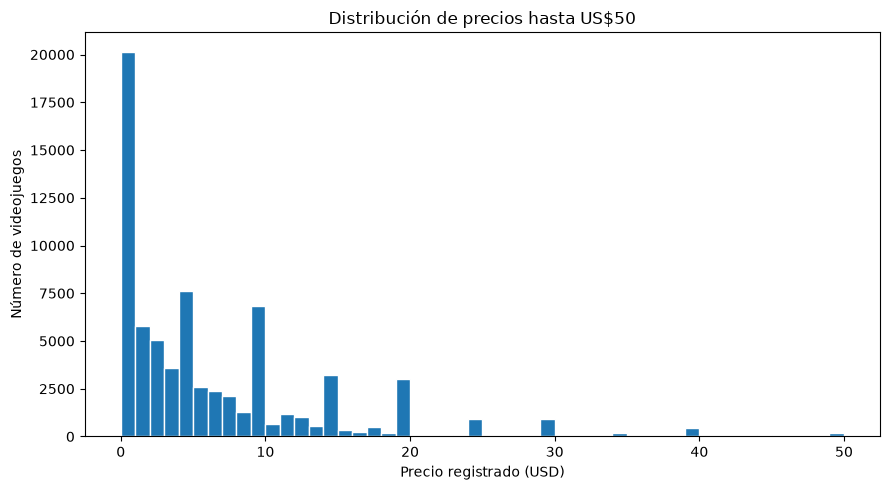

In [51]:
#Crea una figura y un eje de 9 por 5 pulgadas para dibujar la distribución:
fig, ax = plt.subplots(figsize=(9, 5))

#Selecciona solo precios de hasta 50 USD para que las barras sean legibles:
precios_visibles = df.loc[df["Price"] <= 50, "Price"]

#Construye el histograma en 50 intervalos, con bordes blancos para separar barras:
ax.hist(precios_visibles, bins=50, edgecolor="white")

#Establece el significado de ejes y un título que explicita el recorte visual:
ax.set(xlabel="Precio registrado (USD)", ylabel="Número de videojuegos", title="Distribución de precios hasta US$50")

#Ajusta automáticamente los márgenes para reducir el riesgo de texto cortado:
fig.tight_layout()

#Guarda la figura en la carpeta resultados:
fig.savefig(SALIDA / "01_histograma_precios.png", dpi=160)

#Muestra la figura:
plt.show()

**Interpretación :** La distribución muestra una concentración importante de videojuegos en precios bajos y una menor presencia de títulos con precios elevados. Esto coincide con que la media (7.22 USD) sea superior a la mediana (4.99 USD). Para mejorar la visualización se muestran precios de hasta 50 USD, sin eliminar los valores mayores de la base original.

### Gráfico de todos los tramos de precio
 Complementa el histograma sin excluir ninguno de los rangos de precios.

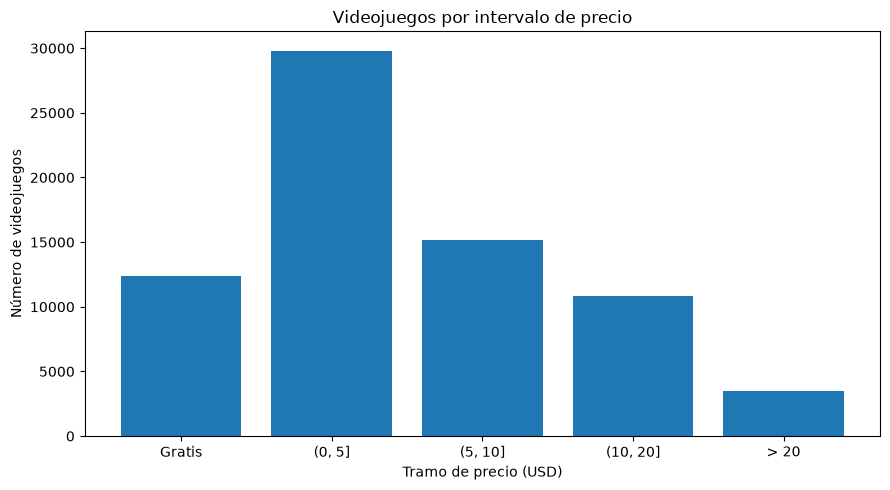

In [52]:
#Crea la figura donde representaremos la frecuencia de cada intervalo:
fig, ax = plt.subplots(figsize=(9, 5))

#Dibuja barras: en el eje horizontal coloca las etiquetas de tramo y en el vertical el número de juegos:
ax.bar(conteo_precios.index.astype(str), conteo_precios.values)

#Agrega ejes descriptivos y un título que permite interpretar las categorías:
ax.set(xlabel="Tramo de precio (USD)", ylabel="Número de videojuegos", title="Videojuegos por intervalo de precio")

#Ajusta márgenes para que las etiquetas no queden cortadas:
fig.tight_layout()

#Guarda la visualización:
fig.savefig(SALIDA / "02_tramos_precio.png", dpi=160)

#La muestra en pantalla:
plt.show()

**Interpretación:** Los tramos permiten comparar el peso relativo de juegos gratuitos y de diferentes niveles de precio. El intervalo de precios mayores que cero y de hasta 5 USD concentra la mayor cantidad de videojuegos, con 29,815 registros. Esto confirma el predominio de videojuegos de precios bajos en el conjunto de datos.

### Frecuencia de etiquetas de género
Responde qué etiquetas agrupan más videojuegos y permite reconocer claramente a `Indie`, `Action`, `Casual` y `Adventure`.

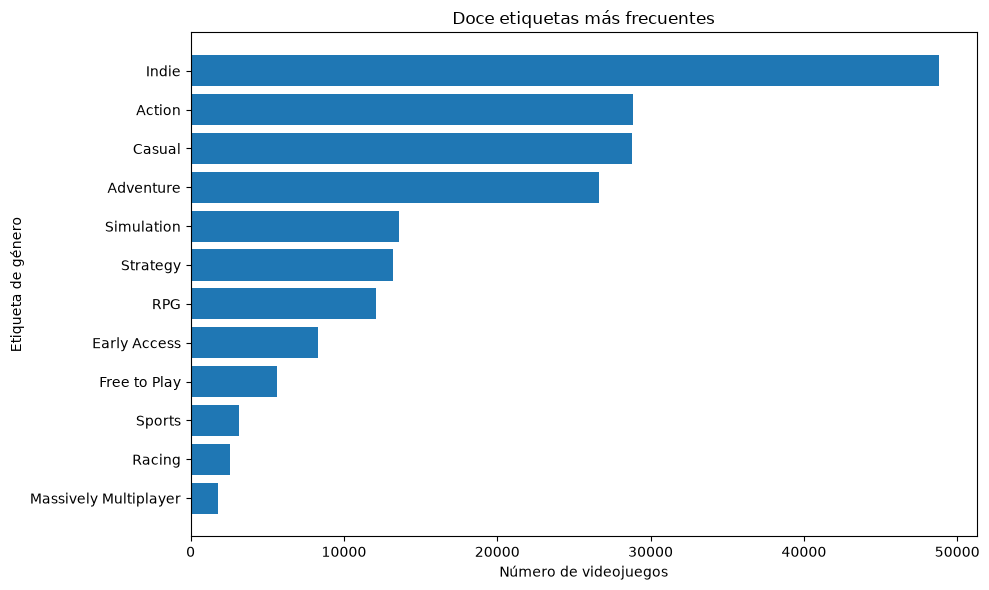

In [53]:
#Elige las doce etiquetas más comunes y las ordena de menor a mayor para graficarlas horizontalmente:
top_generos = frecuencias.head(12).sort_values()

#Crea un área de dibujo ancha para que los nombres de géneros se lean bien:
fig, ax = plt.subplots(figsize=(10, 6))

#Dibuja barras horizontales: una por etiqueta:
ax.barh(top_generos.index, top_generos.values)

#Agrega título y etiquetas de los ejes:
ax.set(xlabel="Número de videojuegos", ylabel="Etiqueta de género", title="Doce etiquetas más frecuentes")
#Ajusta márgenes para evitar que el texto se corte:
fig.tight_layout()

#Guarda la figura de frecuencias:
fig.savefig(SALIDA / "03_frecuencia_generos.png", dpi=160)

#Muestra la figura:
plt.show()

**Interpretación:** Indie es la categoría con mayor cantidad de videojuegos registrados, seguida de Action, Casual y Adventure. Esta información permite identificar dónde se concentra la oferta de títulos, pero no permite determinar cuáles son los más populares entre los jugadores.

### Diagrama de cajas de precios de pago por género
Facilita comparar la posición central y dispersión de precios de pago entre grupos.

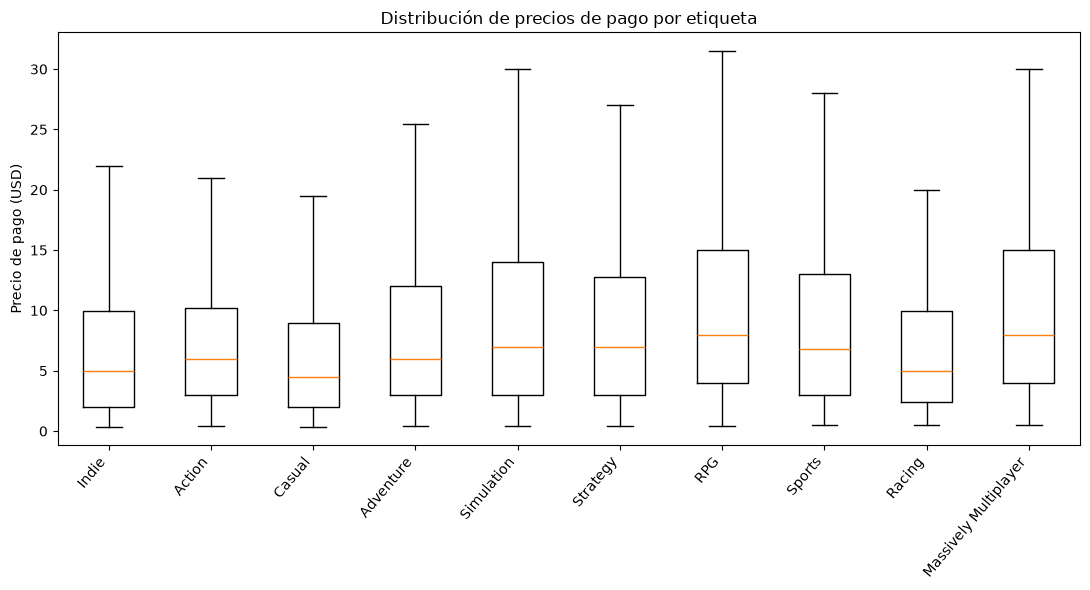

In [54]:
#Crea una lista de series de precios positivos: una por etiqueta en 'GENEROS_JUEGO':
valores_caja = [comparacion.loc[(comparacion["Genero"] == g) & (comparacion["Price"] > 0), "Price"] for g in GENEROS_JUEGO]

#Crea la figura del diagrama de cajas:
fig, ax = plt.subplots(figsize=(11, 6))

#Dibuja cajas con medianas y cuartiles; 'showfliers=False' oculta visualmente puntos extremos, sin eliminarlos de los cálculos:
ax.boxplot(valores_caja, showfliers=False)

#Pone los nombres de las diez etiquetas en el eje horizontal y los gira 50 grados para facilitar su lectura:
ax.set_xticks(range(1, len(GENEROS_JUEGO) + 1), GENEROS_JUEGO, rotation=50, ha="right")

#Agrega el título y la unidad de precio en el eje vertical:
ax.set(ylabel="Precio de pago (USD)", title="Distribución de precios de pago por etiqueta")

#Ajusta los márgenes de la figura:
fig.tight_layout()

#Guarda la gráfica de cajas:
fig.savefig(SALIDA / "04_cajas_precios_por_genero.png", dpi=160)

#Muestra la imagen.
plt.show()

**Interpretación:** Los diagramas de cajas permiten observar diferencias tanto en los precios centrales como en la dispersión entre géneros. RPG y Massively Multiplayer presentan medianas de precios de pago más elevadas que Casual, aunque las distribuciones pueden superponerse. Los valores extremos se ocultan en la figura para facilitar su lectura, pero se conservan en los datos.

### Medianas de precio de pago por género
Resume las diferencias de precio con una estadística robusta y fácilmente explicable.

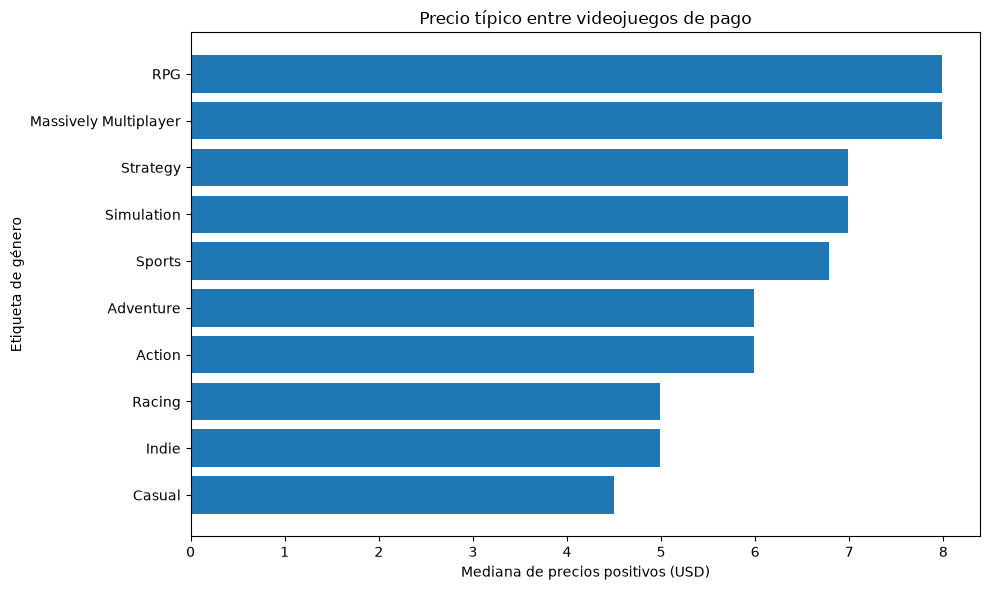

In [55]:
#Ordena los géneros de menor a mayor mediana de precio de pago para facilitar la comparación:
orden_precio = precios_genero.sort_values("mediana_de_pago")

#Crea una figura donde representaremos un resumen por grupo:
fig, ax = plt.subplots(figsize=(10, 6))

#Dibuja las medianas positivas en barras horizontales:
ax.barh(orden_precio["Genero"], orden_precio["mediana_de_pago"])

#Explica en los ejes que estamos mostrando, solo los precios mayores que cero:
ax.set(xlabel="Mediana de precios positivos (USD)", ylabel="Etiqueta de género", title="Precio típico entre videojuegos de pago")

#Ajusta los márgenes de visualización:
fig.tight_layout()

#Guarda la figura en la carpeta de resultados:
fig.savefig(SALIDA / "05_mediana_precios_pago.png", dpi=160)

#Muestra el gráfico:
plt.show()

**Interpretación:** Los géneros RPG y Massively Multiplayer presentan las mayores medianas de precios positivos, con 7.99 USD, mientras que Casual registra 4.50 USD. Esta comparación permite identificar diferencias en el precio típico de los videojuegos de pago, sin considerar los gratuitos.

### Participación: proporción con Peak CCU positivo
Indica en qué géneros es más común encontrar un pico positivo registrado, independientemente del tamaño del género.

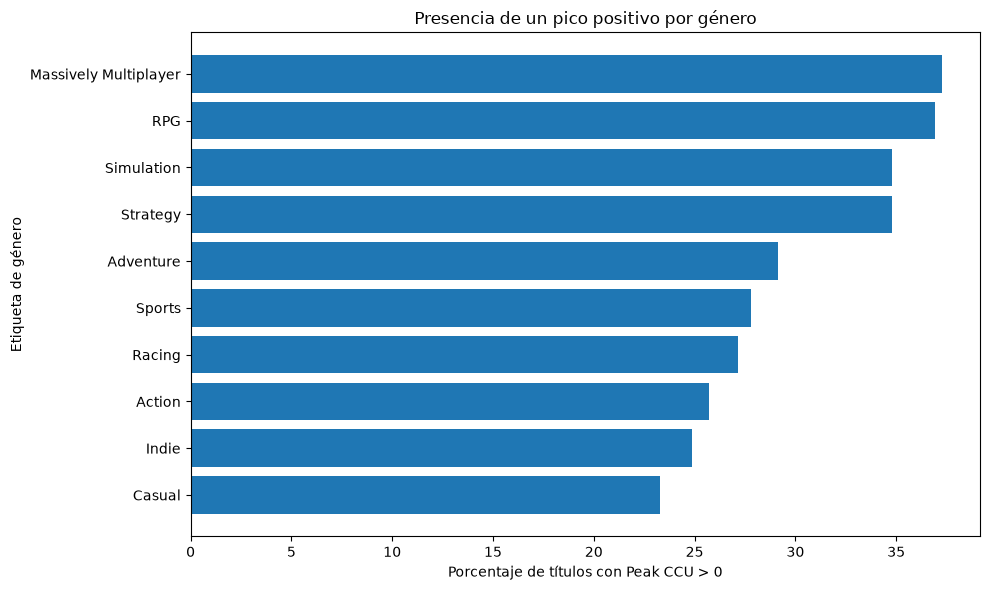

In [56]:
#Ordena la tabla desde la menor hasta la mayor fracción de videojuegos con concurrencia positiva:
orden_ccu = participacion_genero.sort_values("porcentaje_ccu_positivo")
#Crea el lienzo para el gráfico.
fig, ax = plt.subplots(figsize=(10, 6))

#Representa el porcentaje de juegos con un 'Peak CCU' mayor que cero por etiqueta:
ax.barh(orden_ccu["Genero"], orden_ccu["porcentaje_ccu_positivo"])

#Identifica claramente qué se midió y evita usar una etiqueta genérica como “popularidad”:
ax.set(xlabel="Porcentaje de títulos con Peak CCU > 0", ylabel="Etiqueta de género", title="Presencia de un pico positivo por género")

#Ajusta márgenes:
fig.tight_layout()

#Guarda el gráfico:
fig.savefig(SALIDA / "06_proporcion_ccu_positivo.png", dpi=160)

#Mostrar:
plt.show()

**Interpretación:** Massively Multiplayer y RPG presentan las mayores proporciones de títulos con picos de concurrencia positivos, mientras que Casual e Indie registran proporciones menores. Esto sugiere diferencias en la concurrencia registrada entre géneros, aunque un valor de cero no demuestra que el videojuego nunca haya tenido jugadores.

### Participación: mediana de picos positivos
Complementa la proporción con pico positivo: mide la magnitud típica en los juegos que sí tienen valores positivos.

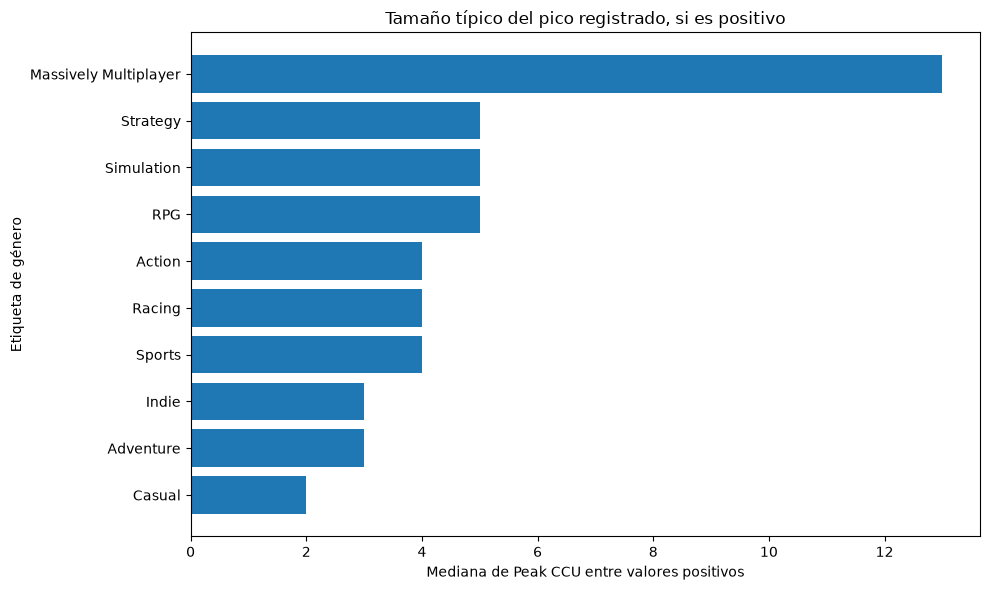

In [57]:
#Ordena los géneros según la mediana del pico positivo registrado:
orden_mediana = participacion_genero.sort_values("mediana_ccu_positivos")

#Crea el área de dibujo:
fig, ax = plt.subplots(figsize=(10, 6))

#Dibuja barras de la mediana de CCU solo entre juegos con valor positivo:
ax.barh(orden_mediana["Genero"], orden_mediana["mediana_ccu_positivos"])

#Aclara en los ejes que la estadística es condicional y no representa el valor típico de todos los títulos:
ax.set(xlabel="Mediana de Peak CCU entre valores positivos", ylabel="Etiqueta de género", title="Tamaño típico del pico registrado, si es positivo")

#Ajusta el espacio de la figura:
fig.tight_layout()

#Guarda la figura:
fig.savefig(SALIDA / "07_mediana_ccu_positivos.png", dpi=160)

#Muestra el gráfico:
plt.show()

**Interpretación:** Entre los videojuegos que registran Peak CCU positivo, Massively Multiplayer presenta la mediana más alta, con 13 jugadores concurrentes, frente a 5 en RPG, Simulation y Strategy. Esto muestra diferencias en la magnitud típica de los picos positivos, sin representar la participación total de todos los videojuegos de cada género.

## Interpretación y conclusiones

**Respuesta a la pregunta 1.** Los precios tienen una distribución concentrada en importes bajos, con **media US$7.22**, **mediana US$4.99**, **17.3% de registros con precio cero** y máximo US$999. Los grupos no presentan el mismo precio típico: por ejemplo, entre los títulos con precio positivo, `RPG` y `Massively Multiplayer` tienen mediana US$7.99, mientras que `Casual` tiene aproximadamente US$4.50.

**Respuesta a la pregunta 2.** `Indie` reúne **48,827 juegos etiquetados**, por encima de `Action` (28,870), `Casual` (28,817) y `Adventure` (26,634). Pero la cantidad de títulos no equivale a concurrencia: entre las diez etiquetas comparadas, `Massively Multiplayer` presenta la mayor proporción de juegos con `Peak CCU > 0` (**37.29%**) y la mayor mediana de picos positivos (**13**). `RPG` registra una proporción cercana (**36.94%**) y mediana positiva de **5**.

**Decisiones de calidad que sostienen el resultado:** (1) no inventamos géneros para los 2,439 casos faltantes; (2) descomponemos los campos multietiqueta para comparar correctamente; (3) conservamos precios extremos y ceros sin confundirlos con ausencias; (4) separamos la probabilidad observada de un pico positivo de su magnitud condicional.


### Verificaciones al terminar
Terminamos con controles sencillos de trazabilidad y reproducibilidad.

In [58]:
#Comprueba que la base original sigue conteniendo el mismo número de identificadores únicos:
print("Número final de juegos originales:", df["AppID"].nunique())

#Muestra los géneros no informados y verifica que se conservaron en el análisis global:
print("Juegos sin género:", df["Genres_limpios"].isna().sum())

#Explica que no se sobrescribió el CSV fuente con ninguna transformación:
print("Archivo original inalterado: el análisis se hizo sobre una copia en memoria")

#Cuenta los archivos generados en la carpeta de resultados:
print("Figuras y tablas:", len(list(SALIDA.iterdir())))

Número final de juegos originales: 71716
Juegos sin género: 2439
Archivo original inalterado: el análisis se hizo sobre una copia en memoria
Figuras y tablas: 10


Interpretación: Se confirmó que la base conserva sus 71,716 identificadores únicos y que los 2,439 videojuegos sin información de género permanecen registrados. Además, se generaron diez archivos de resultados sin sobrescribir el CSV original, lo que permite conservar la información fuente y reproducir el análisis.